# Designing a hedge for a euro swap portfolio

George Dharma

How much swap notional should the desk commit when a hedge that fits one set of rate shocks can perform poorly on other curve shapes?

A €20m limit produces a €179k maximum loss across six design shocks and a €235k maximum loss across four further shocks. The three potential hedges receive or pay fixed against six-month Euribor. All numbers use the fully repriced swaps and an up-front charge on executed notional.

## Read or reproduce the work

The saved tables and chart can be read immediately. To execute the cells, open this notebook from the extracted Python project. Set `rebuild = True` below to regenerate the outputs from the supplied inputs.

In [1]:
from pathlib import Path
import subprocess
import sys
import pandas as pd
from IPython.display import Image

# If the notebook was downloaded separately, unpack the Python package alongside it.
here = Path.cwd()
candidates = [here, here.parent, here / "George_Dharma_09_Rates_Python", here.parent / "George_Dharma_09_Rates_Python"]
root = next((p for p in candidates if (p / "run_analysis.py").exists() and (p / "rates").is_dir()), None)
if root is None:
    raise FileNotFoundError("Extract the complete research package and open this notebook from its project folder.")
sys.path.insert(0, str(root))
output = root / "outputs"
rebuild = False
if rebuild or not (output / "budget_summary.csv").exists() or not (output / "budget_tradeoff.png").exists():
    subprocess.run([sys.executable, str(root / "run_analysis.py")], cwd=root, check=True)
print("Project data and output files are ready.")

Project data and output files are ready.


## Understand the budget decision

The loss figures below are positive euro amounts. The additional shocks remain outside the optimisation. Each limit counts both pay-fixed and receive-fixed amounts at their absolute size.

In [2]:
results = pd.read_csv(output / "budget_summary.csv")
columns = ["policy", "gross_notional_m", "entry_cost", "fit_worst_loss", "other_worst_loss"]
results[columns].round(1)

,policy,gross_notional_m,entry_cost,fit_worst_loss,other_worst_loss
0,Cap €0m,0.0,0.0,469202.1,377327.3
1,Cap €10m,10.0,4136.9,239834.7,328279.9
2,Cap €20m,20.0,7706.0,178889.8,235460.3
3,Cap €40m,40.0,14844.1,57000.0,316914.0
4,Cap €60m,52.4,11890.5,29001.9,503507.9
5,Parallel neutral,9.8,4902.2,242077.1,392912.3


## Portfolio results at a glance

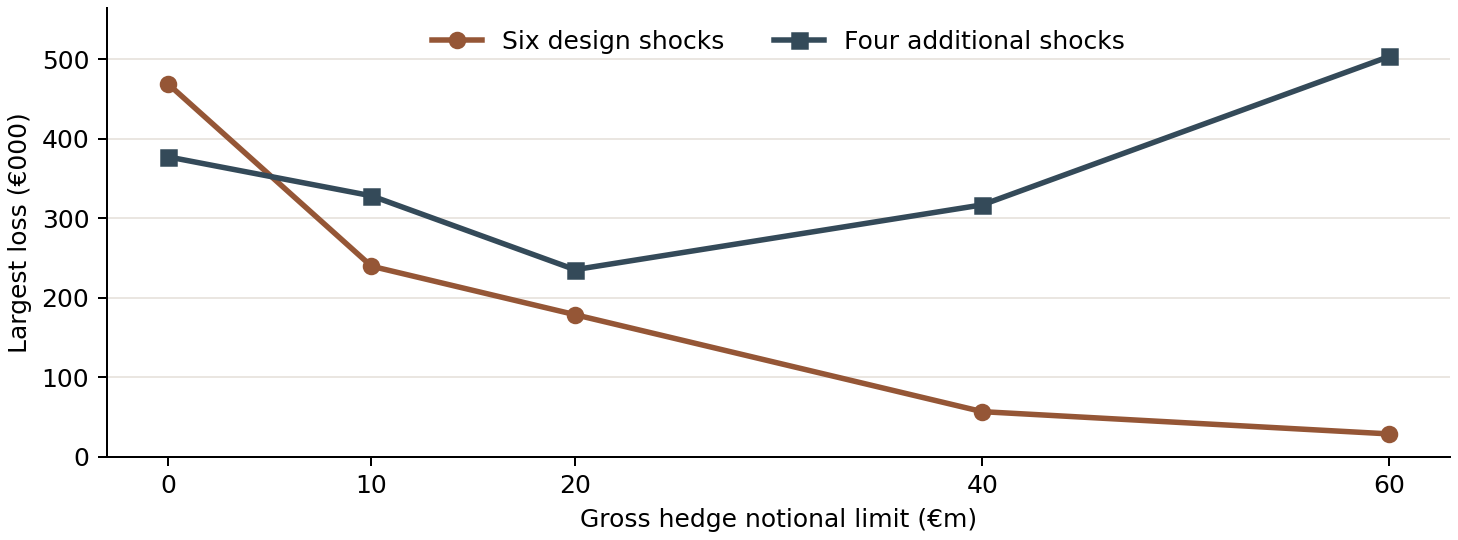

In [3]:
Image(filename=str(output / "budget_tradeoff.png"), width=810)

## Change the hedge budget

Change budget_m and run the cell to derive new positions from fully repriced unit hedges. Positive amounts pay fixed. The additional losses use the same fitted positions.

In [4]:
from rates.stress_budget import minimax
budget_m = 20
scenarios = pd.read_csv(output / "budget_stresses.csv").query('policy == "Cap €0m"')
fees = pd.read_csv(output / "budget_positions.csv").query('policy == "Cap €0m"').unit_cost.to_numpy()
initial = scenarios.unhedged_pnl.to_numpy()
unit = scenarios[["unit_2y_pnl", "unit_5y_pnl", "unit_10y_pnl"]].to_numpy()
fit = scenarios["sample"].eq("Design").to_numpy()
hedge, worst_design = minimax(initial[fit], unit[fit], fees, budget_m)
after_cost = initial + unit @ hedge - abs(hedge) @ fees
print(f"2Y, 5Y, 10Y signed EUR millions: {hedge.round(3)}")
print(f"Worst design loss €{worst_design:,.0f}; worst additional loss €{-after_cost[~fit].min():,.0f}")
pd.DataFrame({"Shock":scenarios.shock, "Net P&L (EUR)":after_cost.round()})

2Y, 5Y, 10Y signed EUR millions: [ 0.    -9.154 10.846]
Worst design loss €178,890; worst additional loss €235,460


,Shock,Net P&L (EUR)
0,Parallel up 50 bp,-178890.0
1,Parallel down 50 bp,183367.0
2,Steeper curve,-178890.0
3,Flatter curve,164389.0
4,Discount quotes up 25 bp,-24875.0
5,Projection quotes up 25 bp,-80729.0
6,Five-year hump,212678.0
7,Five-year dip,-235460.0
8,Opposing curve basis,21257.0
9,Front-end shock,-169655.0


## Trace the mark to market

Four forward-starting swaps make up the underlying book. The first four rows below exclude the hypothetical hedge instruments. The public market sample supplies the quotes. The portfolio positions and stresses are illustrative.

In [5]:
trades = pd.read_csv(output / "trades.csv").iloc[:4]
print(f"Gross notional €{trades.notional.sum():,.0f}; opening PV €{trades.pv.sum():,.0f}")
trades[["trade_id", "notional", "fixed_rate", "raw_end", "pv"]].round(4)

Gross notional €95,000,000; opening PV €1,588,337


,trade_id,notional,fixed_rate,raw_end,pv
0,S1,35000000,0.0100,2019-03-09,1.068205e+06
1,S2,25000000,0.0060,2023-03-09,-3.789431e+05
2,S3,20000000,0.0125,2028-03-09,9.627166e+05
3,S4,15000000,0.0025,2021-03-09,-6.364127e+04


## Source

Open Source Risk, pinned sample market and curve conventions for 5 February 2016.

[Open the original source](https://github.com/OpenSourceRisk/Engine/tree/3d75a69087911a7e2cf1e6882da7bc27135c0762/Examples/Input)